
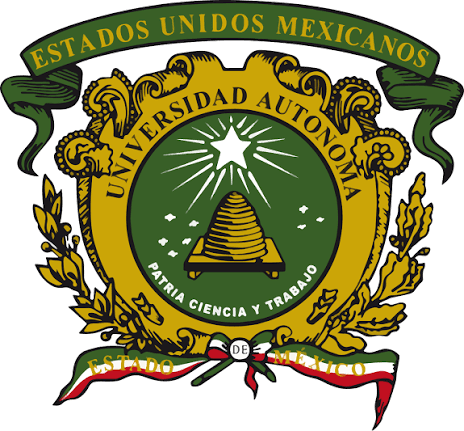

In [7]:
from pathlib import Path
from base64 import b64encode
from IPython.display import HTML, display

# Edita aquí los datos de la portada.
campus = "Centro Universitario UAEM Zumpango"
semestre = "5.º semestre"
turno = "Turno matutino"
asignatura = "Investigación de Operaciones"
practica = "Práctica 4 · Programación lineal"
proyecto = "Asignación de horas de capacitación"

integrantes = [
    "Daniela Cacahuatitla García",
    "Alexander Garcia Gonzales",
    "Rafael Mimbrera Moreno"
]

# Insertar el escudo dentro de la portada.
archivo_escudo = Path("escudo_uaem.png")

if archivo_escudo.is_file():
    imagen = b64encode(archivo_escudo.read_bytes()).decode("ascii")
    escudo = (
        f'<img src="data:image/png;base64,{imagen}" '
        'alt="Escudo de la UAEMéx" '
        'style="width:120px; max-width:27%; height:auto;">'
    )
else:
    escudo = '<div style="color:#2e501d; font-weight:bold;">UAEMéx</div>'

nombres = "<br>".join(integrantes)

portada = f"""
<div style="
    box-sizing:border-box;
    position:relative;
    max-width:760px;
    min-height:790px;
    margin:16px auto;
    padding:52px 35px 50px 65px;
    background:#ffffff;
    color:#171717;
    font-family:Arial, sans-serif;
    text-align:center;
    border:1px solid #dddddd;
">
    <div style="
        position:absolute; top:0; bottom:0; left:0;
        width:30px; background:#2e501d;
        border-right:10px solid #aa8b30;
    "></div>

    <div style="
        display:flex; align-items:center; justify-content:center;
        gap:20px; margin-bottom:45px;
    ">
        {escudo}
        <div style="font-size:20px; font-weight:bold; line-height:1.35;">
            Universidad Autónoma del Estado de México
        </div>
    </div>

    <div style="font-size:17px; font-weight:bold; color:#2e501d;">
        {campus.upper()}
    </div>

    <div style="margin-top:36px; font-size:16px; line-height:1.8;">
        <strong>{semestre}</strong><br>
        {turno}
    </div>

    <div style="margin-top:32px; font-size:18px; font-weight:bold;">
        {asignatura}
    </div>

    <h1 style="margin:14px 0 8px; font-size:28px; color:#2e501d;">
        {practica}
    </h1>

    <div style="font-size:17px;">{proyecto}</div>

    <div style="margin-top:44px; font-size:16px; line-height:1.8;">
        <strong>Integrantes</strong><br>
        {nombres}
    </div>
</div>
"""

display(HTML(portada))

## Asignación de horas de capacitación

Un laboratorio universitario dispone de 8 horas de uso de sala y
12 horas de apoyo técnico para impartir dos talleres. Cada hora del
taller de redes usa 1 hora de sala y 2 horas de apoyo técnico.
Cada hora del taller de programación usa 1 hora de sala y 1 hora
de apoyo técnico.

Para el ejercicio, asignamos un beneficio de 5 puntos por cada hora
de redes y 4 puntos por cada hora de programación. El objetivo es
determinar cuántas horas asignar a cada taller para maximizar el
beneficio sin exceder los recursos disponibles.

## Variables, función objetivo y restricciones

- **x:** horas del taller de redes.
- **y:** horas del taller de programación.

**Maximizar** $Z = 5x + 4y$.

Restricciones:

- $x + y \leq 8$ por las horas disponibles de sala.
- $2x + y \leq 12$ por las horas disponibles de apoyo técnico.
- $x, y \geq 0$ porque las horas asignadas no pueden ser negativas.

## Resolución con SciPy

La función `linprog` minimiza. Para maximizar $5x+4y$, le pasamos
los coeficientes de $-5x-4y$. Al final cambiamos el signo del valor
obtenido para recuperar el beneficio máximo.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display

coeficientes = [-5, -4]
restricciones = [[1, 1], [2, 1]]
recursos = [8, 12]

solucion = linprog(
    c=coeficientes,
    A_ub=restricciones,
    b_ub=recursos,
    bounds=[(0, None), (0, None)],
    method="highs"
)

if not solucion.success:
    raise RuntimeError(solucion.message)

x_optima, y_optima = solucion.x
beneficio_maximo = -solucion.fun

print(f"Horas de redes: {x_optima:g}")
print(f"Horas de programación: {y_optima:g}")
print(f"Beneficio máximo: {beneficio_maximo:g} puntos")

Horas de redes: 4
Horas de programación: 4
Beneficio máximo: 36 puntos


## Verificación por el método gráfico

La región factible contiene todos los pares de horas que cumplen
ambas restricciones. Para encontrar el máximo, evaluamos la función
objetivo en sus vértices.

La intersección de las dos restricciones se obtiene resolviendo
$x+y=8$ y $2x+y=12$. Al restar la primera ecuación de la segunda,
obtenemos $x=4$. Al sustituirlo, obtenemos $y=4$.

,Horas de redes,Horas de programación,Beneficio
0,0.0,0.0,0.0
1,6.0,0.0,30.0
2,4.0,4.0,36.0
3,0.0,8.0,32.0


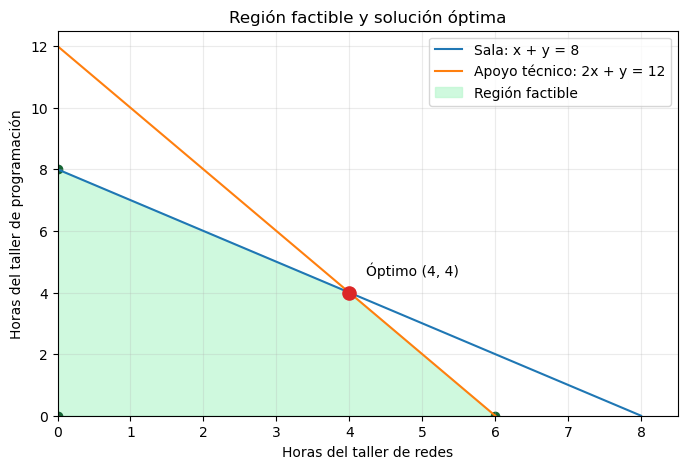

In [6]:
cruce = np.linalg.solve(restricciones, recursos)
vertices = np.array([[0, 0], [6, 0], cruce, [0, 8]])

tabla = pd.DataFrame(vertices, columns=["Horas de redes", "Horas de programación"])
tabla["Beneficio"] = 5 * vertices[:, 0] + 4 * vertices[:, 1]
display(tabla)

assert np.isclose(tabla["Beneficio"].max(), beneficio_maximo)

x = np.linspace(0, 8, 200)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, 8 - x, label="Sala: x + y = 8")
ax.plot(x, 12 - 2 * x, label="Apoyo técnico: 2x + y = 12")
ax.fill(
    vertices[:, 0], vertices[:, 1],
    color="#bbf7d0", alpha=0.7, label="Región factible"
)
ax.scatter(vertices[:, 0], vertices[:, 1], color="#166534")
ax.scatter(x_optima, y_optima, color="#dc2626", s=90, zorder=3)
ax.annotate(
    "Óptimo (4, 4)", (x_optima, y_optima),
    xytext=(12, 12), textcoords="offset points"
)

ax.set(
    xlim=(0, 8.5), ylim=(0, 12.5),
    xlabel="Horas del taller de redes",
    ylabel="Horas del taller de programación",
    title="Región factible y solución óptima"
)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Interpretación de resultados

La mejor asignación es de **4 horas de redes y 4 horas de programación**.
El beneficio máximo es **5(4) + 4(4) = 36 puntos**.

Se usan las 8 horas disponibles de sala porque $4+4=8$. También se
usan las 12 horas de apoyo técnico porque $2(4)+4=12$.

## Conclusión individual

En esta práctica aprendí a convertir un problema de asignación de recursos en un modelo de programación lineal. Primero identifiqué qué debía decidir. En este caso, las variables representaban las horas que se asignarían al taller de redes y al taller de programación. Después formulé el beneficio total y escribí las restricciones de acuerdo con los recursos disponibles en el laboratorio. Este paso me ayudó a entender que cada número tiene un significado. Por ejemplo, el coeficiente de la variable de redes en la restricción de apoyo técnico indica que se necesitan dos horas de apoyo por cada hora de ese taller.

Al resolver el modelo con SciPy, obtuve una asignación de 4 horas de redes y 4 horas de programación, con un beneficio máximo de 36 puntos. Para comprobar el resultado, evalué la función objetivo en los vértices de la región factible. Observé que dedicar seis horas únicamente al taller de redes genera 30 puntos y dedicar ocho horas únicamente al taller de programación genera 32 puntos. Comparar esas opciones con los 36 puntos de la combinación óptima me permitió entender por qué conviene repartir las horas en este ejercicio.

La gráfica me ayudó a interpretar el punto (4, 4), porque se encuentra en la intersección de las restricciones de sala y de apoyo técnico. Al sustituir los valores en ambas expresiones, comprobé que la solución utiliza las 8 horas de sala y las 12 horas de apoyo técnico. Con esta práctica aprendí a justificar una decisión desde el planteamiento del modelo hasta la comprobación del resultado. También entendí que, si cambian los recursos disponibles o los beneficios asignados a cada taller, tendría que resolver de nuevo el modelo para saber qué distribución conviene.

## Conclusión del equipo

Como equipo, aplicamos la programación lineal para decidir cómo distribuir dos recursos limitados entre un taller de redes y otro de programación. Acordamos representar las horas de cada taller con dos variables y expresar el beneficio total mediante una función objetivo. Posteriormente establecimos las restricciones de sala y de apoyo técnico. Al revisar el modelo, observamos que el taller de redes aporta más puntos por hora, pero también requiere más apoyo técnico. Esa diferencia influyó en la distribución final.

La solución que obtuvimos fue asignar 4 horas a cada taller. Con esta distribución, el beneficio alcanza 36 puntos y se utilizan por completo las 8 horas de sala y las 12 horas de apoyo técnico. Verificamos el resultado de SciPy con el método gráfico. La región factible nos permitió identificar qué combinaciones respetaban los dos límites, y la evaluación de los vértices confirmó en qué punto se alcanzaba el mayor beneficio.

Concluimos que la programación lineal puede apoyar la planeación de actividades cuando varios proyectos compiten por los mismos recursos. En este caso, el modelo nos permitió justificar cuántas horas asignar a cada taller y cuánto apoyo técnico requería esa decisión. En una aplicación real, podríamos usar las horas efectivamente disponibles y definir el beneficio de acuerdo con el objetivo del laboratorio. Si el objetivo fuera atender a más estudiantes, por ejemplo, podríamos plantear el beneficio en función del número de participantes que puede atender cada taller.